# PathLens: data exploration

A walk through the data and the numbers behind the product, using the real code in `backend/`.

**Everything here is synthetic.** The training sentences were written by one author, the routes are invented, and
the simulated reports come from the demo generator. Nothing in this notebook measures how accurate PathLens is on
real streets or real citizen reports. It shows *how the machinery behaves*, so you can check it matches what the
product claims: unknown is never "fine", small samples are smoothed, old reports fade, and a close call is called a
close call.

| Part | Question |
|---|---|
| 1 | What does the report classifier learn from, and where does it hesitate? |
| 2 | How fast do reports fade, and how does confidence depend on coverage and freshness? |
| 3 | How does the concern score react to route length, trust tiers and where the evidence sits? |
| 4 | When does a change of weights flip which route wins? |
| 5 | What do the invented corridor, its simulated reports and its information gaps look like? |

Run it from the repository root with `pip install -r requirements.txt`, then `jupyter lab notebooks/`.

In [1]:
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

# Find the repository root whether the notebook is run from notebooks/ or from the top.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT / "backend"))

from ai.classify_report import CONFIDENCE_THRESHOLD, ReportClassifier, _pipeline  # noqa: E402
from services import freshness  # noqa: E402
from services.risk_engine import CATEGORIES, DEFAULT_WEIGHTS, SCORED_FACTORS, Config, ReportPoint, RouteGeom, analyse_route, rank_stability  # noqa: E402

# One colour per category, in a fixed order (a palette checked for colour-blind separation of neighbours).
CAT_ORDER = ["streetlight", "poor_lighting", "obstruction", "footpath", "visibility"]
PALETTE = dict(zip(CAT_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
LABEL = {k: v.label for k, v in CATEGORIES.items()}
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e1"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def ink_on(rgba):
    # Black or white text, whichever reads better on this background (WCAG relative luminance).
    lin = [c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    lum = 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2]
    return "white" if (1.05 / (lum + 0.05)) > ((lum + 0.05) / 0.05) else INK

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c8c7c2", "axes.labelcolor": MUTED, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})
NOW = datetime(2026, 10, 1, tzinfo=timezone.utc)  # a fixed "today" keeps every number below reproducible
print("repository:", ROOT.name, "| scored factors:", SCORED_FACTORS, "| default weights:", DEFAULT_WEIGHTS)

repository: PathLens | scored factors: ('lighting', 'hazard') | default weights: {'lighting': 35.0, 'hazard': 30.0}


## 1. The report classifier

It reads the free text of a report and *suggests* a category. It is a small TF-IDF + logistic-regression model
trained on 90 hand-written sentences (`data/synthetic/classifier_seed.csv`). A person always confirms the category,
and a moderator makes the final call.

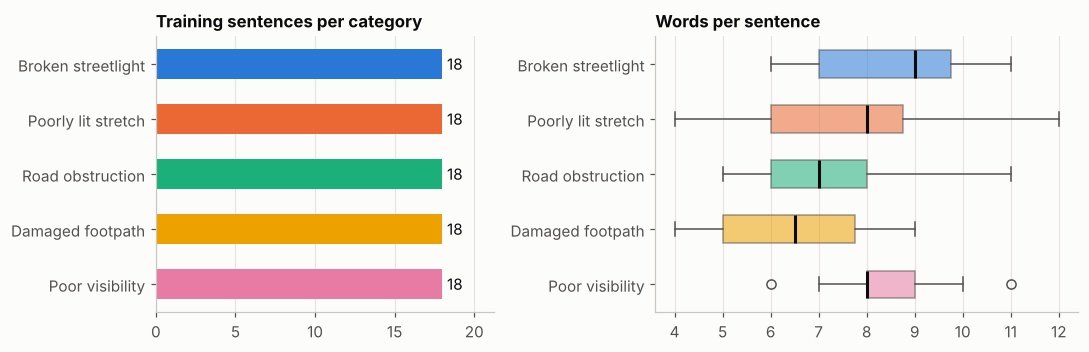

,count,mean,min,max
category,,,,
streetlight,18.0,8.3,6.0,11.0
poor_lighting,18.0,7.7,4.0,12.0
obstruction,18.0,7.4,5.0,11.0
footpath,18.0,6.5,4.0,9.0
visibility,18.0,8.6,6.0,11.0


In [2]:
seed = pd.read_csv(ROOT / "data" / "synthetic" / "classifier_seed.csv")
seed["words"] = seed["text"].str.split().str.len()
counts = seed["category"].value_counts().reindex(CAT_ORDER)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.3), gridspec_kw={"width_ratios": [1, 1.25]})
names = [LABEL[c] for c in CAT_ORDER]
bars = left.barh(names[::-1], counts.values[::-1], color=[PALETTE[c] for c in CAT_ORDER][::-1], height=0.55)
left.bar_label(bars, padding=3, color=INK)
left.set_title("Training sentences per category")
left.set_xlim(0, counts.max() * 1.18)
left.grid(axis="y", visible=False)

box = right.boxplot([seed.loc[seed.category == c, "words"] for c in CAT_ORDER][::-1], vert=False, widths=0.5, patch_artist=True,
                    medianprops={"color": INK, "linewidth": 2}, whiskerprops={"color": MUTED}, capprops={"color": MUTED}, flierprops={"markeredgecolor": MUTED})
for patch, c in zip(box["boxes"], CAT_ORDER[::-1]):
    patch.set(facecolor=PALETTE[c], alpha=0.55, edgecolor=MUTED)
right.set_yticks(range(1, 6))
right.set_yticklabels(names[::-1])
right.set_title("Words per sentence")
right.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

seed.groupby("category")["words"].describe()[["count", "mean", "min", "max"]].round(1).reindex(CAT_ORDER)

**What it shows.** The set is balanced (18 sentences per category) and the sentences are short: 4 to 12 words,
6 to 9 on average. Real reports will not arrive in even numbers or in such tidy phrasing, so expect to retrain once
moderator-labelled reports exist.

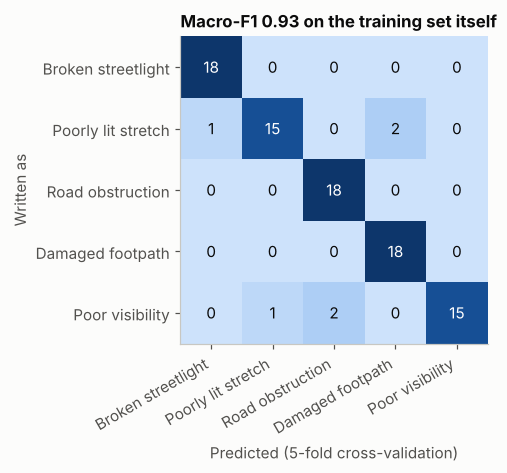

The API reports the same number: 0.932
Trained on a small synthetic seed set written by one author, so the score is optimistic and says nothing about accuracy on real reports. The classifier only suggests; a person or a moderator decides.


,Broken streetlight,Poorly lit stretch,Road obstruction,Damaged footpath,Poor visibility
Broken streetlight,18,0,0,0,0
Poorly lit stretch,1,15,0,2,0
Road obstruction,0,0,18,0,0
Damaged footpath,0,0,0,18,0
Poor visibility,0,1,2,0,15


In [3]:
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

clf = ReportClassifier()
pred = cross_val_predict(_pipeline(), clf.texts, clf.labels, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=7))
macro_f1 = f1_score(clf.labels, pred, average="macro")
cm = pd.DataFrame(confusion_matrix(clf.labels, pred, labels=CAT_ORDER), index=names, columns=names)

fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.imshow(cm.values, cmap=BLUES, vmin=0, vmax=cm.values.max())
ax.set_xticks(range(5)); ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(5)); ax.set_yticklabels(names)
ax.grid(False)
for i in range(5):
    for j in range(5):
        v = cm.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color=ink_on(BLUES(v / cm.values.max())))
ax.set_xlabel("Predicted (5-fold cross-validation)")
ax.set_ylabel("Written as")
ax.set_title(f"Macro-F1 {macro_f1:.2f} on the training set itself")
plt.tight_layout()
plt.show()
print("The API reports the same number:", clf.info["cv_macro_f1"])
print(clf.info["note"])
cm

**What it shows.** Cross-validated macro-F1 is 0.93, and 84 of the 90 sentences are classified as written. The 6
mistakes sit between neighbouring ideas: a poorly lit stretch read as a damaged footpath (2) or a broken streetlight
(1), and poor visibility read as a road obstruction (2) or a poorly lit stretch (1).

That score looks great and means little: the same author wrote every sentence, so the test sentences resemble the
training sentences. A fairer question is what the model does with sentences it has not seen, including ones written
differently from the training set.

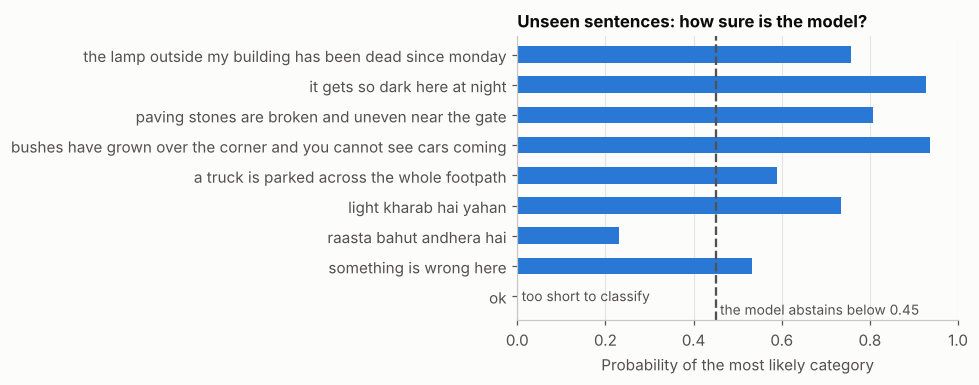

,sentence,suggestion,how,top probability,needs review
0,the lamp outside my building has been dead sin...,Broken streetlight,model,0.758,False
1,it gets so dark here at night,Poorly lit stretch,model,0.927,False
2,paving stones are broken and uneven near the gate,Damaged footpath,model,0.808,False
3,bushes have grown over the corner and you cann...,Poor visibility,model,0.937,False
4,a truck is parked across the whole footpath,Road obstruction,model,0.590,False
5,light kharab hai yahan,Broken streetlight,model,0.734,False
6,raasta bahut andhera hai,none,none,0.230,True
7,something is wrong here,Poorly lit stretch,model,0.532,False
8,ok,none,none,NaN,True


In [4]:
probe = [
    "the lamp outside my building has been dead since monday",
    "it gets so dark here at night",
    "paving stones are broken and uneven near the gate",
    "bushes have grown over the corner and you cannot see cars coming",
    "a truck is parked across the whole footpath",
    "light kharab hai yahan",                      # Hinglish
    "raasta bahut andhera hai",                    # Hinglish
    "something is wrong here",
    "ok",
]
rows = []
for text in probe:
    r = clf.classify(text)
    rows.append({
        "sentence": text,
        "suggestion": LABEL.get(r.category, "none"),
        "how": r.method,
        "top probability": max(r.probabilities.values()) if r.probabilities else np.nan,
        "needs review": r.needs_review,
    })
table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(table))[::-1]
ax.barh(y, table["top probability"].fillna(0), color="#2a78d6", height=0.55)
ax.axvline(CONFIDENCE_THRESHOLD, color=MUTED, linestyle="--", linewidth=1.5)
ax.text(CONFIDENCE_THRESHOLD + 0.01, -0.45, f"the model abstains below {CONFIDENCE_THRESHOLD}", color=MUTED, fontsize=9, va="center")
ax.text(0.01, 0, "too short to classify", color=MUTED, fontsize=9, va="center")
ax.set_yticks(y); ax.set_yticklabels(table["sentence"])
ax.set_ylim(-0.8, len(table) - 0.4)
ax.set_xlim(0, 1)
ax.set_xlabel("Probability of the most likely category")
ax.set_title("Unseen sentences: how sure is the model?")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
table

**What it shows.** Sentences close to the training wording get a confident suggestion ("it gets so dark here at
night" 0.93, "bushes have grown over the corner..." 0.94). Hinglish is hit or miss. "light kharab hai yahan" works
because the word *light* is in the training set (0.73), while "raasta bahut andhera hai" scores 0.23, falls under
the 0.45 threshold and goes to review, which is the right behaviour. The weak spot is the vague sentence: "something
is wrong here" still gets a suggestion (poorly lit, 0.53) because it clears the threshold. That is why the form only
suggests, a person confirms the category and a moderator makes the final call.

## 2. Freshness and confidence

Each category fades at its own speed (`services/freshness.py`): a broken light stays broken until someone repairs
it, while a blocked lane is usually clear within days. Confidence is kept apart from the concern score. It says how
much of a route has recent evidence; it never changes how concerning the route looks.

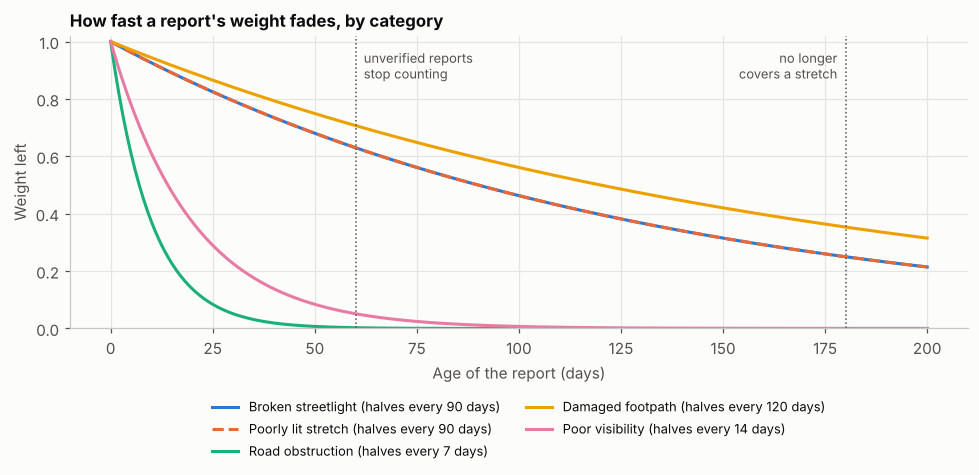

An obstruction reported 14 days ago keeps 0.25 of its weight.


In [5]:
days = np.arange(0, 201)
cfg = Config()
fig, ax = plt.subplots(figsize=(9, 4.6))
for cat in CAT_ORDER:
    half = freshness.HALF_LIFE_DAYS[cat]
    style = "--" if cat == "poor_lighting" else "-"  # same half-life as streetlight, so draw it dashed on top
    ax.plot(days, 0.5 ** (days / half), color=PALETTE[cat], linestyle=style, label=f"{LABEL[cat]} (halves every {half:.0f} days)")
ax.axvline(cfg.unverified_expiry_days, color=MUTED, linewidth=1, linestyle=":")
ax.text(cfg.unverified_expiry_days + 2, 0.97, "unverified reports\nstop counting", color=MUTED, fontsize=8.5, va="top")
ax.axvline(freshness.OBSERVE_DAYS, color=MUTED, linewidth=1, linestyle=":")
ax.text(freshness.OBSERVE_DAYS - 2, 0.97, "no longer\ncovers a stretch", color=MUTED, fontsize=8.5, va="top", ha="right")
ax.set_xlabel("Age of the report (days)")
ax.set_ylabel("Weight left")
ax.set_ylim(0, 1.02)
ax.set_title("How fast a report's weight fades, by category")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
plt.tight_layout()
plt.show()

# The plot uses the formula; check it against the function the engine really calls.
probe_report = ReportPoint("x", "obstruction", 0, 0, "verified", NOW - timedelta(days=14))
assert abs(freshness.decay(probe_report, NOW) - 0.5 ** (14 / freshness.HALF_LIFE_DAYS["obstruction"])) < 1e-12
print("An obstruction reported 14 days ago keeps", round(freshness.decay(probe_report, NOW), 2), "of its weight.")

**What it shows.** Half-lives differ by a factor of 17: 7 days for an obstruction, 14 for poor visibility, 90 for
a streetlight or a poorly lit stretch, 120 for a damaged footpath. An obstruction reported two weeks ago keeps a
quarter of its weight, a broken streetlight reported two weeks ago keeps 90%. These numbers are provisional.

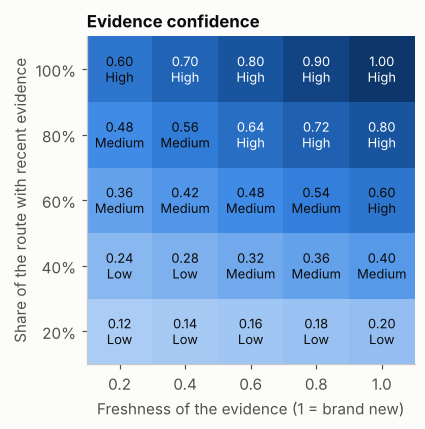

,0.2,0.4,0.6,0.8,1.0
20%,0.12,0.14,0.16,0.18,0.2
40%,0.24,0.28,0.32,0.36,0.4
60%,0.36,0.42,0.48,0.54,0.6
80%,0.48,0.56,0.64,0.72,0.8
100%,0.60,0.70,0.80,0.90,1.0


In [6]:
coverage_levels = [0.2, 0.4, 0.6, 0.8, 1.0]
freshness_levels = [0.2, 0.4, 0.6, 0.8, 1.0]
conf = [[freshness.confidence(c, f) for f in freshness_levels] for c in coverage_levels]
values = pd.DataFrame([[v for v, _ in row] for row in conf], index=[f"{int(c*100)}%" for c in coverage_levels], columns=[f"{f:.1f}" for f in freshness_levels])

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(values.values[::-1], cmap=BLUES, vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(5)); ax.set_xticklabels(values.columns)
ax.set_yticks(range(5)); ax.set_yticklabels(values.index[::-1])
for i, row in enumerate(conf[::-1]):
    for j, (v, label) in enumerate(row):
        ax.text(j, i, f"{v:.2f}\n{label}", ha="center", va="center", fontsize=8.5, color=ink_on(BLUES(v)))
ax.set_xlabel("Freshness of the evidence (1 = brand new)")
ax.set_ylabel("Share of the route with recent evidence")
ax.set_title("Evidence confidence")
plt.tight_layout()
plt.show()
values.round(2)

**What it shows.** Confidence is `coverage x (0.5 + 0.5 x freshness)`, so coverage dominates: completely stale
evidence over the whole route still gives 0.60, while brand-new evidence over a fifth of the route gives only 0.20.
Confidence never moves the concern score; it only says how much to trust it.

## 3. How the concern score behaves

Small helpers build straight routes and put reports where we choose, so each experiment changes one thing.

In [7]:
M_PER_DEG = 111_195.0  # metres per degree along the equator, where these test routes lie


def straight_route(length_m):
    return RouteGeom([(0.0, 0.0), (0.0, length_m / M_PER_DEG)], float(length_m), length_m / 1.4)


def reports_at(length_m, positions_m, category="streetlight", status="verified", age_days=10, reporters=None, prefix="r"):
    out = []
    for k, pos in enumerate(positions_m):
        out.append(ReportPoint(
            id=f"{prefix}{k}", category=category, lat=0.00005, lng=pos / M_PER_DEG, status=status,
            reported_at=NOW - timedelta(days=age_days), reporter_id=(reporters[k % len(reporters)] if reporters else None),
        ))
    return out


def summary(a):
    m = a.metrics
    return {"concern": m.concern_score if m.concern_band != "insufficient" else np.nan, "band": m.concern_band,
            "range": m.concern_range, "coverage %": round(100 * m.coverage), "counted reports": m.counted,
            "gaps": [(g.from_m, g.to_m) for g in a.gaps]}

### 3a. The same issues on a longer route weigh less, and a thin sample is not trusted

`k` verified streetlight reports are spread evenly along routes of 0.5, 1 and 3 km. A gap in a line means the
route has too little evidence to score at all ("not enough data"); it is never drawn as zero.

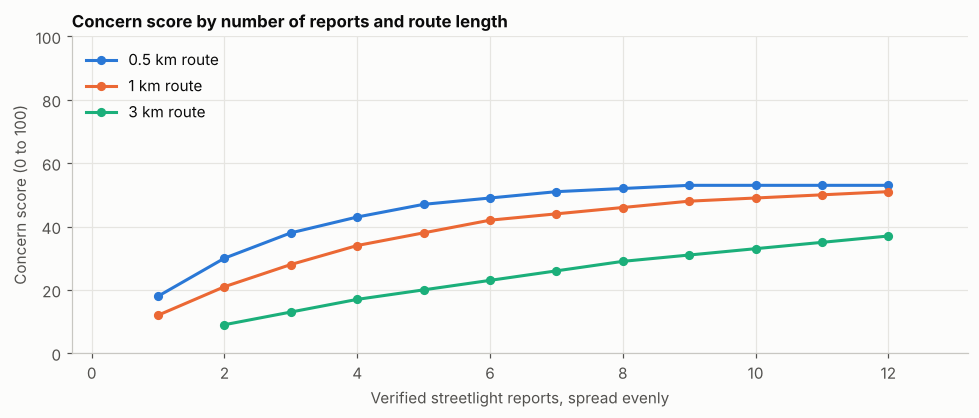

,0.5 km,1 km,3 km
reports,,,
0,n/a (not enough data),n/a (not enough data),n/a (not enough data)
1,18,12,n/a (not enough data)
2,30,21,9
3,38,28,13
4,43,34,17
5,47,38,20
6,49,42,23
7,51,44,26
8,52,46,29


In [8]:
lengths = [500, 1000, 3000]
ks = list(range(0, 13))
grid = {L: [] for L in lengths}
for L in lengths:
    for k in ks:
        pos = [(i + 0.5) * L / k for i in range(k)] if k else []
        grid[L].append(summary(analyse_route(straight_route(L), reports_at(L, pos), NOW)))

colors = {500: "#2a78d6", 1000: "#eb6834", 3000: "#1baf7a"}
fig, ax = plt.subplots(figsize=(9, 3.9))
for L in lengths:
    ax.plot(ks, [r["concern"] for r in grid[L]], marker="o", markersize=5, color=colors[L], label=f"{L / 1000:g} km route")
ax.set_xlabel("Verified streetlight reports, spread evenly")
ax.set_ylabel("Concern score (0 to 100)")
ax.set_xlim(-0.3, 13.2)
ax.set_ylim(0, 100)
ax.set_title("Concern score by number of reports and route length")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

pd.DataFrame({f"{L / 1000:g} km": [("n/a (not enough data)" if np.isnan(r["concern"]) else int(r["concern"])) for r in grid[L]] for L in lengths}, index=pd.Index(ks, name="reports"))

**What it shows.** Six reports score 49 on a 0.5 km route, 42 on 1 km and 23 on 3 km: the same problems matter less
the longer the route. The curves also flatten instead of climbing to 100. With only lighting problems reported the
score cannot pass about 54, because lighting is 35 of the 65 weight points; hazards would add the rest. And a single
report on a 3 km route is "not enough data": it observes about 300 m of 3,000 m, about 10%, under the 20% floor.

### 3b. Trust tiers: how much an unverified report counts

Four streetlight reports in the same spot, in three situations. One person reporting four times is still one voice.
Two independent people corroborating each other count at half weight. A moderator-verified report counts in full.

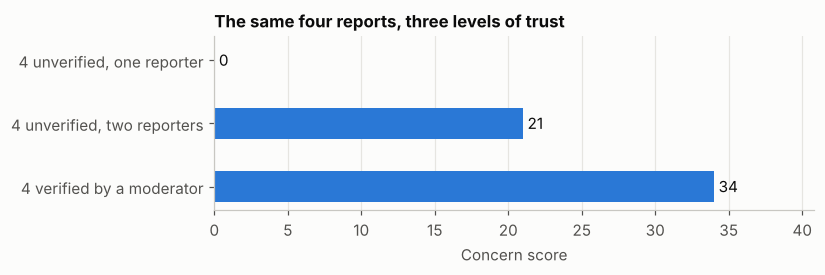

,basis,counted reports,concern,band,coverage %
"4 unverified, one reporter",[unverified],0,0,low,30
"4 unverified, two reporters",[corroborated],4,21,moderate,30
4 verified by a moderator,[verified],4,34,moderate,30


In [9]:
spot = [420, 440, 460, 480]
cases = {
    "4 unverified, one reporter": reports_at(1000, spot, status="unverified", reporters=["alice"]),
    "4 unverified, two reporters": reports_at(1000, spot, status="unverified", reporters=["alice", "bob"]),
    "4 verified by a moderator": reports_at(1000, spot, status="verified"),
}
rows = {}
for name, reports in cases.items():
    a = analyse_route(straight_route(1000), reports, NOW)
    rows[name] = {**summary(a), "basis": sorted({e.basis for e in a.evidence})}
trust = pd.DataFrame(rows).T[["basis", "counted reports", "concern", "band", "coverage %"]]

fig, ax = plt.subplots(figsize=(7.6, 2.6))
y = np.arange(len(trust))[::-1]
bars = ax.barh(y, trust["concern"].astype(float), color="#2a78d6", height=0.5)
ax.bar_label(bars, padding=3, color=INK)
ax.set_yticks(y); ax.set_yticklabels(trust.index)
ax.set_xlim(0, max(10, trust["concern"].astype(float).max() * 1.2))
ax.set_xlabel("Concern score")
ax.set_title("The same four reports, three levels of trust")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
trust

**What it shows.** One person reporting four times counts for nothing: 0 reports counted. Two independent people
count at half weight and score 21, against 34 for the same four reports verified by a moderator (about 60%, not 50%,
because the score is not linear in weight).

Look at the first row, though: it scores 0 and is labelled *low*, with 30% coverage, even though someone reported
a broken light there four times. See *An open design question* at the end of section 5.

### 3c. Where the evidence sits matters as much as how much there is

Six verified reports on a 1 km route, either bunched at the start or spread out. The score reflects only what was
reported; the *information gaps* say where nothing is known.

In [10]:
layouts = {"bunched in the first 150 m": [30, 60, 90, 110, 130, 150], "spread along the route": [80, 250, 420, 590, 760, 930]}
rows = {n: summary(analyse_route(straight_route(1000), reports_at(1000, p), NOW)) for n, p in layouts.items()}
pd.DataFrame(rows).T[["concern", "band", "range", "coverage %", "gaps"]]

,concern,band,range,coverage %,gaps
bunched in the first 150 m,42,moderate,"(42, 53)",30,"[(300, 1000)]"
spread along the route,42,moderate,"(42, 42)",100,[]


**What it shows.** Both layouts score 42, so the score alone would hide the difference. The rest does not: bunched
evidence has a range of 42 to 53 and covers 30% of the route, spread evidence has a range of 42 to 42 and covers
100%. The bunched layout also lists its information gap (300 m to 1,000 m). That is why confidence, the range and the
gaps are shown beside the score.

## 4. When does the winner depend on the weights?

The weights (lighting 35, road hazards 30 by default) are provisional and nobody has validated them. So the
product asks a second question: if the weights are nudged, does the best route change? `rank_stability` tries 200
random nudges of up to ±50% and reports the share of trials each route wins.

Two invented comparisons on 1.5 km routes. In the first, one route has only hazard reports and the other only
lighting reports, so the weights decide who wins. In the second, one route is simply worse on both counts.

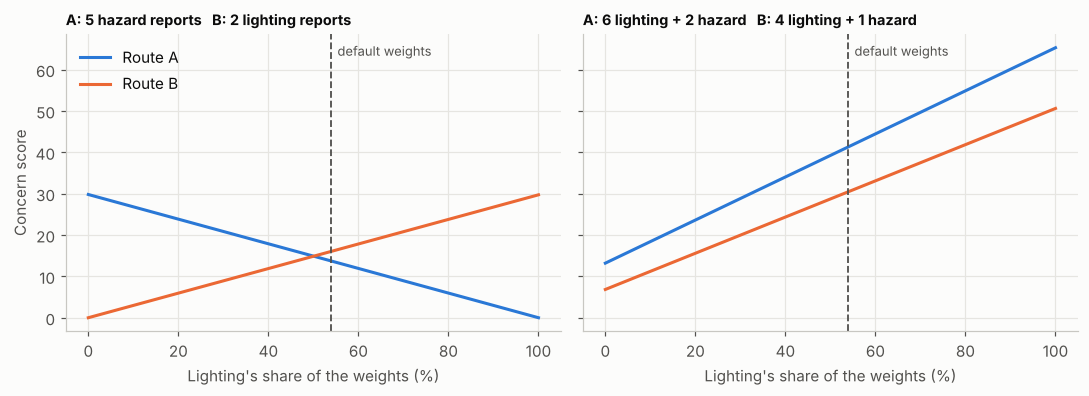

,scenario,label,share of trials each route wins,ties
0,A: 5 hazard reports B: 2 lighting reports,close call,"{'A': 0.5, 'B': 0.36}",28
1,A: 6 lighting + 2 hazard B: 4 lighting + 1 h...,stable,"{'A': 0.0, 'B': 1.0}",0


In [11]:
L = 1500
spread = lambda n: [(i + 0.5) * L / n for i in range(n)]


def scenario(a_lighting, a_hazard, b_lighting, b_hazard):
    def build(name, nl, nh):
        reports = reports_at(L, spread(nl), "streetlight", prefix=name + "l") if nl else []
        reports += reports_at(L, spread(nh), "obstruction", prefix=name + "h") if nh else []
        return analyse_route(straight_route(L), reports, NOW, name=name)
    return [build("A", a_lighting, a_hazard), build("B", b_lighting, b_hazard)]


scenarios = {"A: 5 hazard reports   B: 2 lighting reports": scenario(0, 5, 2, 0), "A: 6 lighting + 2 hazard   B: 4 lighting + 1 hazard": scenario(6, 2, 4, 1)}
shares = np.linspace(0, 100, 101)  # the lighting weight as a share of the total, in percent

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), sharey=True)
default_share = 100 * DEFAULT_WEIGHTS["lighting"] / sum(DEFAULT_WEIGHTS.values())
verdicts = []
for ax, (title, pair) in zip(axes, scenarios.items()):
    for a, color in zip(pair, ["#2a78d6", "#eb6834"]):
        f = a.factor_exact
        ax.plot(shares, (f["lighting"] * shares + f["hazard"] * (100 - shares)) / 100, color=color, label=f"Route {a.name}")
    ax.axvline(default_share, color=MUTED, linestyle="--", linewidth=1.2)
    ax.text(default_share + 1.5, 0.97, "default weights", color=MUTED, fontsize=8.5, va="top", transform=ax.get_xaxis_transform())
    ax.set_title(title, fontsize=9.5)
    ax.set_xlabel("Lighting's share of the weights (%)")
    st = rank_stability(pair)
    verdicts.append({"scenario": title, "label": st.label, "share of trials each route wins": st.best_share, "ties": st.ties})
axes[0].set_ylabel("Concern score")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()
pd.DataFrame(verdicts)

**What it shows.** In the first comparison route A (hazards only) wins 50% of the 200 weight nudges, route B wins
36% and 14% are ties (28 trials), so the product says *close call*: the lines cross near the default weights. In the
second comparison B has fewer problems of both kinds, wins every trial and the ranking is *stable* whatever the
weights. A *close call* is not a failure of the method. It is the method saying the data cannot separate two routes.

## 5. The invented corridor

The two routes between the placeholder places Alpha and Beta (`data/roads/demo_corridor.geojson`), the simulated
reports along them (`data/synthetic/simulated_reports.csv`) and the mapped streetlights, help points and shops
(`data/roads/osm_snapshot_synthetic.json`, which is *not* OpenStreetMap data). Crosses mark **information gaps**:
stretches of 200 m or more with no recent evidence.

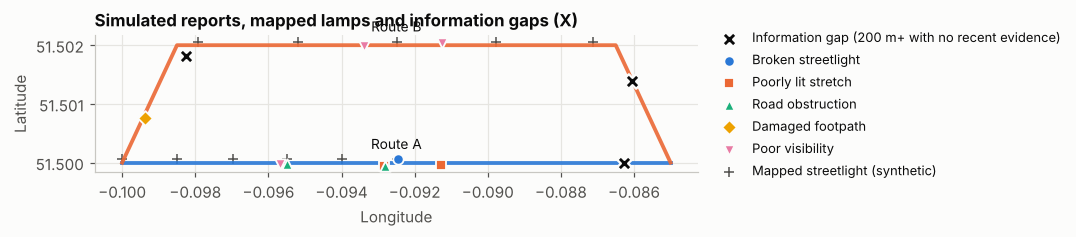

,band,concern,coverage %,counted reports,gaps
Route A,moderate,26,67,6,"[(800, 1038)]"
Route B,low,0,38,0,"[(900, 1321), (0, 400)]"


In [12]:
import json
from services.osm_baseline import parse_overpass
from services.risk_engine import FeaturePoint

corridor = json.loads((ROOT / "data" / "roads" / "demo_corridor.geojson").read_text())
lines = {f["properties"]["name"]: f for f in corridor["features"] if f["geometry"]["type"] == "LineString"}
sim = pd.read_csv(ROOT / "data" / "synthetic" / "simulated_reports.csv", parse_dates=["reported_at", "verified_at"])
snapshot = parse_overpass(json.loads((ROOT / "data" / "roads" / "osm_snapshot_synthetic.json").read_text()))
features = [FeaturePoint(f["kind"], f["lat"], f["lng"]) for f in snapshot]

analyses = {}
for name, f in lines.items():
    geom = RouteGeom([(lat, lng) for lng, lat in f["geometry"]["coordinates"]], f["properties"]["distance_m"], f["properties"]["duration_s"])
    pts = [ReportPoint(r.id, r.category, r.lat, r.lng, r.status, r.reported_at.to_pydatetime(),
                       None if pd.isna(r.verified_at) else r.verified_at.to_pydatetime(), simulated=True) for r in sim.itertuples()]
    analyses[name] = analyse_route(geom, pts, NOW, name=name, features=features)

markers = dict(zip(CAT_ORDER, ["o", "s", "^", "D", "v"]))  # shape repeats the colour, so identity never rests on colour alone
fig, ax = plt.subplots(figsize=(10, 4.4))
for (name, a), color in zip(analyses.items(), ["#2a78d6", "#eb6834"]):
    xs = [lng for lat, lng in a.route.coords]; ys = [lat for lat, lng in a.route.coords]
    ax.plot(xs, ys, color=color, linewidth=2.5, alpha=0.9, zorder=2)
    ax.annotate(name, (xs[len(xs) // 2], ys[len(ys) // 2]), xytext=(0, 9), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax.scatter([g.lng for g in a.gaps], [g.lat for g in a.gaps], marker="X", s=90, color=INK, edgecolor=SURFACE, linewidth=1.5, zorder=4,
               label="Information gap (200 m+ with no recent evidence)" if name == "Route A" else None)
for cat in CAT_ORDER:
    s = sim[sim.category == cat]
    ax.scatter(s.lng, s.lat, marker=markers[cat], s=46, color=PALETTE[cat], edgecolor=SURFACE, linewidth=1.2, zorder=3, label=LABEL[cat])
lamps = [f for f in snapshot if f["kind"] == "lamp"]
ax.scatter([f["lng"] for f in lamps], [f["lat"] for f in lamps], marker="+", s=36, color=MUTED, linewidth=1, zorder=1, label="Mapped streetlight (synthetic)")
ax.set_aspect(1 / np.cos(np.radians(51.5)))
ax.ticklabel_format(useOffset=False)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Simulated reports, mapped lamps and information gaps (X)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8.5)
plt.tight_layout()
plt.show()

pd.DataFrame({n: summary(a) for n, a in analyses.items()}).T[["band", "concern", "coverage %", "counted reports", "gaps"]]

**What it shows.** Route A has six verified reports, 67% coverage and a score of 26 (moderate), with one gap
(800 m to 1,038 m). Route B has no counted report at all: its three reports are single, unverified ones. It still comes
out as *low* with 38% coverage, and lists two gaps (0 to 400 m, 900 to 1,321 m).

### An open design question

A report that is unverified and has no independent second reporter is shown but not counted. It still counts as
**coverage**: it marks the stretches around it as observed. So a route whose only evidence is uncorroborated reports
of a problem can be labelled "Low reported concern" (section 3b, first row, and Route B above), with coverage and
confidence that come from the very reports the score ignores. A test (`test_a_single_unverified_report_is_shown_but_not_counted`)
asserts that coverage rises, so this was a deliberate choice, but it works against the rule that unknown is never
read as fine.

Three ways to resolve it, none applied here because the engine is unchanged by this notebook:

1. Take coverage only from evidence that counts, or from resolved reports, so a single unverified report adds none
   and the route reads "Not enough data" until someone verifies or corroborates it.
2. Keep the coverage, and add a fourth band such as "Unverified reports only".
3. Keep the behaviour and state it plainly in the methodology.

This is a decision for the project owner.

## What this notebook cannot tell you

- **Real accuracy.** Every number comes from invented routes, invented reports and sentences written by one person.
  The classifier needs real, moderator-labelled reports before any accuracy figure means something.
- **Whether the weights are right.** They are provisional. Section 4 shows when the answer depends on them, not which
  weights are correct. Testing them takes people who walk these routes.
- **Anything about a real place.** The corridor is a placeholder in the map's default position.
- **Safety.** PathLens compares *reported conditions on routes*. It does not predict crime and nothing here says a
  route is safe.